max |dw1 diff| = 2.3283064365386963e-10
max |dw2 diff| = 1.1175870895385742e-08
Epoch 1/10  loss 1.9857  train acc 35.20%  test acc 35.02%
Epoch 2/10  loss 1.7898  train acc 38.92%  test acc 38.71%
Epoch 3/10  loss 1.7215  train acc 41.12%  test acc 40.36%
Epoch 4/10  loss 1.6792  train acc 42.62%  test acc 42.11%
Epoch 5/10  loss 1.6469  train acc 43.67%  test acc 42.61%
Epoch 6/10  loss 1.6195  train acc 44.90%  test acc 43.06%
Epoch 7/10  loss 1.5959  train acc 45.77%  test acc 44.26%
Epoch 8/10  loss 1.5733  train acc 46.35%  test acc 44.43%
Epoch 9/10  loss 1.5539  train acc 46.97%  test acc 44.81%
Epoch 10/10  loss 1.5354  train acc 47.81%  test acc 45.65%


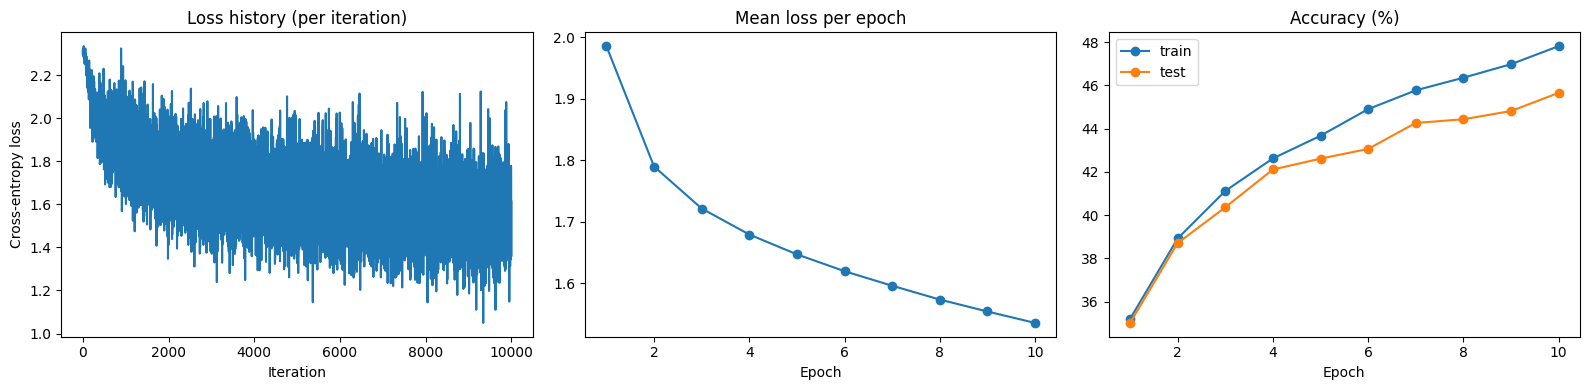

Training accuracy: 47.81%
Test accuracy:     45.65%


In [4]:
# %% [markdown]
# # Q1: Two-layer dense network (100 sigmoid hidden nodes) with cross-entropy, manual backprop
# Changes vs Listing 1: (a) hidden layer of 100 nodes + sigmoid, (b) softmax cross-entropy loss, (c) 10 epochs.

# %%
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)

# %% 1. Data loading (num_workers=0 avoids multiprocessing problems on Windows/Jupyter)
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# %% 2. Parameters
Din = 3 * 32 * 32      # input size
H = 100                # (a) hidden nodes
K = 10                 # classes
std = 1e-2             # 1e-5 (single-layer listing) is too small for two layers: gradients vanish

w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

epochs = 10            # (c)
lr = 5e-2
lr_decay = 0.95
reg = 0.0              # L2 regularisation strength

# %% Helper functions
def forward(x):
    z1 = x.mm(w1) + b1
    h = torch.sigmoid(z1)          # (a) sigmoid activation
    logits = h.mm(w2) + b2
    return h, logits

def cross_entropy(logits, labels):
    """(b) softmax + cross-entropy, averaged over the batch."""
    log_probs = torch.log_softmax(logits, dim=1)
    return -log_probs[torch.arange(len(labels)), labels].mean()

def evaluate(loader):
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, logits = forward(x)
            loss_sum += cross_entropy(logits, labels).item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            total += len(labels)
    return 100 * correct / total, loss_sum / total

# %% Optional: gradient check of the manual backprop against autograd (one batch)
inputs, labels = next(iter(trainloader))
x = inputs.view(inputs.shape[0], -1)
N = x.shape[0]
h, logits = forward(x)
probs = torch.softmax(logits, dim=1)
dlogits = (probs - nn.functional.one_hot(labels, K).float()) / N
dw2_manual = h.t().mm(dlogits)
dz1 = dlogits.mm(w2.t()) * h * (1 - h)
dw1_manual = x.t().mm(dz1)

w1a, w2a = w1.clone().requires_grad_(), w2.clone().requires_grad_()
loss_a = cross_entropy(torch.sigmoid(x.mm(w1a) + b1).mm(w2a) + b2, labels)
loss_a.backward()
print("max |dw1 diff| =", (w1a.grad - dw1_manual).abs().max().item())
print("max |dw2 diff| =", (w2a.grad - dw2_manual).abs().max().item())

# %% 3. Training loop
loss_history = []
train_acc_hist, test_acc_hist, epoch_loss_hist = [], [], []

for t in range(epochs):
    running_loss = 0.0
    for i, (inputs, labels) in enumerate(trainloader):
        Ntr = inputs.shape[0]
        x = inputs.view(Ntr, -1)
        y_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, logits = forward(x)
        loss = cross_entropy(logits, labels) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation (manual)
        probs = torch.softmax(logits, dim=1)
        dlogits = (probs - y_onehot) / Ntr           # dL/dlogits for softmax + CE
        dw2 = h.t().mm(dlogits) + 2 * reg * w2
        db2 = dlogits.sum(dim=0)
        dh = dlogits.mm(w2.t())
        dz1 = dh * h * (1 - h)                       # sigmoid derivative
        dw1 = x.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w2 -= lr * dw2
        b2 -= lr * db2
        w1 -= lr * dw1
        b1 -= lr * db1

    lr *= lr_decay
    tr_acc, _ = evaluate(trainloader)
    te_acc, _ = evaluate(testloader)
    epoch_loss_hist.append(running_loss / len(trainloader))
    train_acc_hist.append(tr_acc)
    test_acc_hist.append(te_acc)
    print(f"Epoch {t + 1}/{epochs}  loss {epoch_loss_hist[-1]:.4f}  "
          f"train acc {tr_acc:.2f}%  test acc {te_acc:.2f}%")

# %% 4. Plots
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(loss_history); ax[0].set_title('Loss history (per iteration)')
ax[0].set_xlabel('Iteration'); ax[0].set_ylabel('Cross-entropy loss')
ax[1].plot(range(1, epochs + 1), epoch_loss_hist, marker='o'); ax[1].set_title('Mean loss per epoch')
ax[1].set_xlabel('Epoch')
ax[2].plot(range(1, epochs + 1), train_acc_hist, marker='o', label='train')
ax[2].plot(range(1, epochs + 1), test_acc_hist, marker='o', label='test')
ax[2].set_title('Accuracy (%)'); ax[2].set_xlabel('Epoch'); ax[2].legend()
plt.tight_layout(); plt.show()

# %% 5. Final accuracies
train_acc, _ = evaluate(trainloader)
test_acc, _ = evaluate(testloader)
print(f"Training accuracy: {train_acc:.2f}%")
print(f"Test accuracy:     {test_acc:.2f}%")

Device: cpu


100.0%
100.0%
100.0%
100.0%


LeNet-5 parameters: 61706
Epoch  1/10  train loss 0.3112 acc 91.03% | test loss 0.0916 acc 97.26%  (19.6s)
Epoch  2/10  train loss 0.0774 acc 97.68% | test loss 0.0767 acc 97.70%  (20.8s)
Epoch  3/10  train loss 0.0544 acc 98.26% | test loss 0.0456 acc 98.60%  (22.7s)
Epoch  4/10  train loss 0.0419 acc 98.68% | test loss 0.0365 acc 98.86%  (22.2s)
Epoch  5/10  train loss 0.0345 acc 98.93% | test loss 0.0492 acc 98.49%  (27.3s)
Epoch  6/10  train loss 0.0285 acc 99.12% | test loss 0.0395 acc 98.78%  (22.0s)
Epoch  7/10  train loss 0.0239 acc 99.21% | test loss 0.0364 acc 98.82%  (22.5s)
Epoch  8/10  train loss 0.0210 acc 99.32% | test loss 0.0450 acc 98.62%  (23.5s)
Epoch  9/10  train loss 0.0173 acc 99.46% | test loss 0.0358 acc 98.89%  (22.6s)
Epoch 10/10  train loss 0.0153 acc 99.51% | test loss 0.0359 acc 98.86%  (27.2s)
Modern CNN parameters: 104650
Epoch  1/10  train loss 0.1415 acc 95.78% | test loss 0.0417 acc 98.65%  (79.8s)
Epoch  2/10  train loss 0.0489 acc 98.44% | test loss

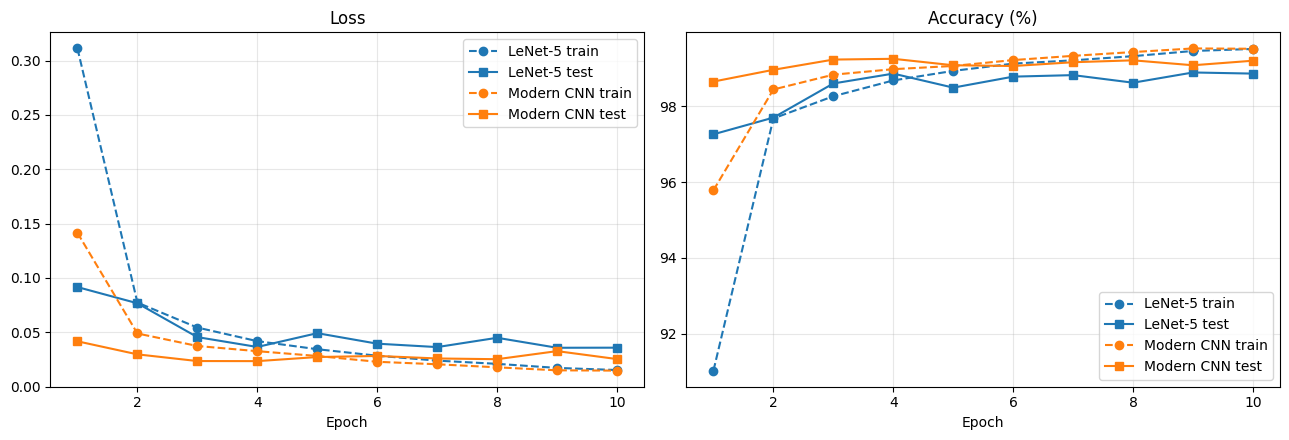

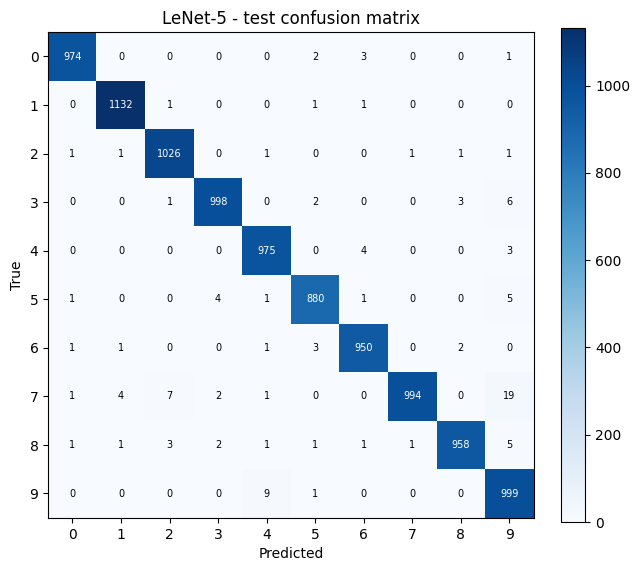

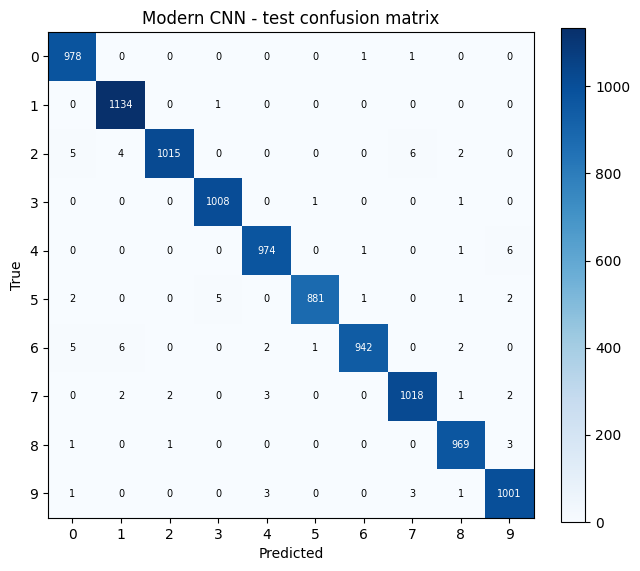

Model           Params   Train acc   Test acc
LeNet-5          61706      99.51%     98.86%
Modern CNN      104650      99.76%     99.20%


In [5]:
# %% [markdown]
# # Q2: LeNet-5 vs a modern small CNN (3 conv layers + BatchNorm + Dropout) on MNIST

# %%
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

# %% Data (same for both models)
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))])
trainset = torchvision.datasets.MNIST('./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST('./data', train=False, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True, num_workers=0)
testloader = torch.utils.data.DataLoader(testset, batch_size=256, shuffle=False, num_workers=0)

# %% Models
class LeNet5(nn.Module):
    """Classic LeNet-5: conv(6,5x5) - pool - conv(16,5x5) - pool - 120 - 84 - 10 (tanh, avg-pool).
    padding=2 in the first conv lets the 28x28 MNIST image match the original 32x32 input."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5, padding=2), nn.Tanh(), nn.AvgPool2d(2),    # 6x14x14
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2))             # 16x5x5
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(),
            nn.Linear(84, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


class ModernCNN(nn.Module):
    """3 conv blocks (Conv-BN-ReLU-MaxPool) + dropout + linear classifier."""
    def __init__(self, p_drop=0.4):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1),
                                 nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))  # 128x3x3
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop),
                                        nn.Linear(128 * 3 * 3, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

# %% Training / evaluation utilities
criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss_sum += criterion(out, y).item() * len(y)
        pred = out.argmax(1)
        correct += (pred == y).sum().item()
        total += len(y)
        all_preds.append(pred.cpu()); all_labels.append(y.cpu())
    return loss_sum / total, 100 * correct / total, torch.cat(all_preds), torch.cat(all_labels)

def train_model(model, epochs=10, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    hist = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    for ep in range(epochs):
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        t0 = time.time()
        for x, y in trainloader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
        te_loss, te_acc, _, _ = evaluate(model, testloader)
        hist['train_loss'].append(loss_sum / total); hist['train_acc'].append(100 * correct / total)
        hist['test_loss'].append(te_loss);           hist['test_acc'].append(te_acc)
        print(f"Epoch {ep + 1:2d}/{epochs}  train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.2f}%"
              f" | test loss {te_loss:.4f} acc {te_acc:.2f}%  ({time.time() - t0:.1f}s)")
    return model, hist

# %% (a) Train LeNet-5
lenet = LeNet5()
print("LeNet-5 parameters:", count_params(lenet))
lenet, hist_lenet = train_model(lenet, epochs=10)

# %% (b) Train the modern CNN under the same conditions (same optimiser, lr, batch size, epochs, seed)
modern = ModernCNN()
print("Modern CNN parameters:", count_params(modern))
modern, hist_modern = train_model(modern, epochs=10)

# %% (c) Per-epoch curves
def plot_hist(histories, names):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ep = range(1, len(histories[0]['train_loss']) + 1)
    for h, n in zip(histories, names):
        l1, = ax[0].plot(ep, h['train_loss'], '--o', label=f'{n} train')
        ax[0].plot(ep, h['test_loss'], '-s', color=l1.get_color(), label=f'{n} test')
        l2, = ax[1].plot(ep, h['train_acc'], '--o', label=f'{n} train')
        ax[1].plot(ep, h['test_acc'], '-s', color=l2.get_color(), label=f'{n} test')
    ax[0].set_title('Loss'); ax[1].set_title('Accuracy (%)')
    for a in ax: a.set_xlabel('Epoch'); a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

plot_hist([hist_lenet, hist_modern], ['LeNet-5', 'Modern CNN'])

# %% Confusion matrices on the test set
def confusion_matrix(preds, labels, k=10):
    return torch.bincount(labels * k + preds, minlength=k * k).reshape(k, k).numpy()

def plot_cm(cm, title):
    fig, ax = plt.subplots(figsize=(6.5, 6))
    im = ax.imshow(cm, cmap='Blues')
    ax.set_title(title); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
    plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

results = {}
for name, model in [('LeNet-5', lenet), ('Modern CNN', modern)]:
    _, te_acc, preds, labels = evaluate(model, testloader)
    _, tr_acc, _, _ = evaluate(model, trainloader)     # train acc in eval mode (no dropout / BN uses running stats)
    results[name] = (tr_acc, te_acc)
    plot_cm(confusion_matrix(preds, labels), f'{name} - test confusion matrix')

# %% Summary table
print(f"{'Model':<12}{'Params':>10}{'Train acc':>12}{'Test acc':>11}")
for name, model in [('LeNet-5', lenet), ('Modern CNN', modern)]:
    print(f"{name:<12}{count_params(model):>10}{results[name][0]:>11.2f}%{results[name][1]:>10.2f}%")